# 02. Pipeline Melhorado - Prova de Conceito (PoC) com Pré-Processamento CLAHE
### Classificação de Patologias em Folhas de Macieira (*Plant Pathology 2020 - FGVC7*)

Este notebook é a versão aprimorada da Prova de Conceito, integrando as etapas de pré-processamento de visão computacional da referência (`image-pre-processing-and-densenet.ipynb`) com o modelo de classificação de alto desempenho (`plant-pathology-2020-eda-models.ipynb`):

1. **Pré-Processamento com OpenCV (CLAHE no Canal V do HSV):**
   - Aplicação de *Contrast Limited Adaptive Histogram Equalization* (CLAHE) no canal V (*Value*) do espaço de cor HSV.
   - Realça contraste morfológico das lesões (*rust*, *scab*, *multiple_diseases*) sem distorcer o balanço de cores e mantendo o formato RGB de 3 canais exigido pela `DenseNet121`.
2. **Resolução Completa (512x512):**
   - Imagens processadas em resolução alta para preservar microtexturas foliares.
3. **Pipeline Assíncrono com `tf.data.Dataset` e Caching em Memória:**
   - O processamento CLAHE é envelopado em `tf.numpy_function` e armazenado em cache (`.cache()`) na 1ª época.
   - A partir da 2ª época, os tensores pré-processados são lidos instantaneamente da memória, eliminando sobrecarga na CPU e operando com 100% de uso da GPU.
4. **Aceleração com Precisão Mista (`mixed_float16`):**
   - Reduz pela metade o uso de memória VRAM e acelera o treino em GPUs Tesla T4 / RTX, com camada de saída em `float32` para estabilidade numérica.
5. **Fine-Tuning de `DenseNet121`:**
   - Base convolucional totalmente treinável com taxa de aprendizado controlada (`1e-4`), *Global Average Pooling*, *Dropout* (0.3) e *Batch Normalization*.
6. **Ponderação por Classe (`class_weight`):**
   - Balanceamento via pesos calculados pelo Scikit-Learn para mitigar o desbalanceamento severo de `multiple_diseases` (~5%).
7. **Callbacks e Monitoramento Contínuo:**
   - `ReduceLROnPlateau`, `EarlyStopping` (paciência de 8 épocas) e `ModelCheckpoint` salvando o melhor modelo por `val_roc_auc` em `models/best_densenet121_clahe.keras`.

## 1. Importação de Bibliotecas e Configuração do Ambiente

In [1]:
import os
import sys
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras import layers, models, applications, callbacks, mixed_precision
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve, auc
from sklearn.utils.class_weight import compute_class_weight

In [2]:
# 1.1 Suporte automático para execução no Google Colab
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    print("[*] Google Colab detectado! Montando Google Drive...")
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_ROOT = '/content/drive/MyDrive/ProjetosRedesNeurais'
    if os.path.exists(PROJECT_ROOT):
        os.chdir(PROJECT_ROOT)
        print(f"[*] Diretório de trabalho: {os.getcwd()}")
    else:
        print(f"[!] Aviso: {PROJECT_ROOT} não encontrado. Executando no diretório atual: {os.getcwd()}")
else:
    print("[*] Ambiente Local detectado!")

[*] Google Colab detectado! Montando Google Drive...
Mounted at /content/drive
[*] Diretório de trabalho: /content/drive/MyDrive/ProjetosRedesNeurais


In [3]:
# 1.2 Configuração de Precisão Mista (Mixed Precision)
try:
    mixed_precision.set_global_policy('mixed_float16')
    print(f"[*] Política de Precisão Mista ativada: {mixed_precision.global_policy().name}")
except Exception as e:
    print(f"[!] Não foi possível ativar mixed precision: {e}")


[*] Política de Precisão Mista ativada: mixed_float16


In [4]:
# 1.3 Detecção e configuração de aceleradores (GPU / TPU / CPU)
strategy = tf.distribute.get_strategy()
print(f"TensorFlow Version: {tf.__version__}")
print(f"Dispositivos físicos disponíveis: {tf.config.list_physical_devices()}")
print(f"Número de réplicas em sincronia: {strategy.num_replicas_in_sync}")

TensorFlow Version: 2.21.0
Dispositivos físicos disponíveis: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'), PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Número de réplicas em sincronia: 1


In [5]:
# 1.4 Diretórios do projeto
DATA_DIR = "data"
IMG_DIR = os.path.join(DATA_DIR, "images")
TRAIN_CSV = os.path.join(DATA_DIR, "train.csv")
TEST_CSV = os.path.join(DATA_DIR, "test.csv")
MODELS_DIR = "models"
GRAPHS_DIR = "graphs"

os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(GRAPHS_DIR, exist_ok=True)

In [6]:
# 1.5 Hiperparâmetros principais
IMG_HEIGHT, IMG_WIDTH = 512, 512
IMG_SHAPE = (IMG_HEIGHT, IMG_WIDTH, 3)
PER_REPLICA_BATCH = 16
BATCH_SIZE = PER_REPLICA_BATCH * strategy.num_replicas_in_sync
AUTOTUNE = tf.data.AUTOTUNE
EPOCHS = 35
SEED = 42

print(f"Resolução: {IMG_SHAPE} | Batch Size: {BATCH_SIZE} | Épocas teto: {EPOCHS}")

Resolução: (512, 512, 3) | Batch Size: 16 | Épocas teto: 35


## 2. Leitura dos Metadados e Divisão Estratificada (Train / Validation)

In [7]:
df = pd.read_csv(TRAIN_CSV)
TARGET_COLS = ["healthy", "multiple_diseases", "rust", "scab"]

df["file_path"] = df["image_id"].apply(lambda x: os.path.join(IMG_DIR, f"{x}.jpg"))
df["label_str"] = df[TARGET_COLS].idxmax(axis=1)
df["label_idx"] = df[TARGET_COLS].values.argmax(axis=1)

# Divisão estratificada (80% treino / 20% validação)
train_df, val_df = train_test_split(
    df,
    test_size=0.20,
    random_state=SEED,
    stratify=df["label_idx"]
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

# Cálculo dos pesos balanceados por classe (Scikit-Learn)
classes = np.unique(train_df["label_idx"])
computed_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["label_idx"].values
)
class_weight_dict = {int(c): float(w) for c, w in zip(classes, computed_weights)}

print(f"Amostras de treino: {len(train_df)}")
print(f"Amostras de validação: {len(val_df)}")
print("\nPesos por classe balanceados (class_weight):")
for idx, col in enumerate(TARGET_COLS):
    qtd = (train_df["label_idx"] == idx).sum()
    print(f"  Classe {idx} ({col:<18}): {qtd:4d} amostras | Peso: {class_weight_dict[idx]:.4f}")

prop_comparison = pd.DataFrame({
    "Treino (N)": train_df["label_str"].value_counts(),
    "Treino (%)": (train_df["label_str"].value_counts() / len(train_df) * 100).round(2),
    "Validação (N)": val_df["label_str"].value_counts(),
    "Validação (%)": (val_df["label_str"].value_counts() / len(val_df) * 100).round(2)
})
display(prop_comparison)

Amostras de treino: 1456
Amostras de validação: 365

Pesos por classe balanceados (class_weight):
  Classe 0 (healthy           ):  413 amostras | Peso: 0.8814
  Classe 1 (multiple_diseases ):   73 amostras | Peso: 4.9863
  Classe 2 (rust              ):  497 amostras | Peso: 0.7324
  Classe 3 (scab              ):  473 amostras | Peso: 0.7696


,Treino (N),Treino (%),Validação (N),Validação (%)
label_str,,,,
rust,497,34.13,125,34.25
scab,473,32.49,119,32.60
healthy,413,28.37,103,28.22
multiple_diseases,73,5.01,18,4.93


## 3. Pré-Processamento OpenCV: CLAHE no Espaço HSV (Canal V)

### Justificativa Metodológica:
- O algoritmo **CLAHE** (*Contrast Limited Adaptive Histogram Equalization*) atenua o efeito de iluminação irregular sob luz solar natural no pomar e aumenta a visibilidade das lesões foliares.
- Aplicamos no **canal V (*Value*) do HSV**: a luminância é equalizada de forma adaptativa sem distorcer o tom da folha (Hue/Saturation). Ao converter de volta para RGB, mantemos a compatibilidade nativa de 3 canais com os pesos pré-treinados do ImageNet.

In [8]:
def apply_clahe_rgb(img_rgb, clip_limit=2.0, tile_grid_size=(8, 8)):
    """
    Aplica CLAHE no canal V do espaço HSV e retorna uma imagem RGB com 3 canais.
    """
    if img_rgb.dtype != np.uint8:
        img_rgb = np.clip(img_rgb, 0, 255).astype(np.uint8)

    img_hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_grid_size)
    img_hsv[:, :, 2] = clahe.apply(img_hsv[:, :, 2])
    img_enhanced = cv2.cvtColor(img_hsv, cv2.COLOR_HSV2RGB)
    return img_enhanced

# Inspeção visual lado a lado: Original vs. CLAHE para cada uma das 4 classes
fig, axes = plt.subplots(4, 2, figsize=(10, 16))

for i, cls_name in enumerate(TARGET_COLS):
    sample_path = train_df[train_df["label_str"] == cls_name].iloc[0]["file_path"]
    bgr = cv2.imread(sample_path)
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    rgb_resized = cv2.resize(rgb, (IMG_WIDTH, IMG_HEIGHT))
    clahe_resized = apply_clahe_rgb(rgb_resized)

    axes[i, 0].imshow(rgb_resized)
    axes[i, 0].set_title(f"Original: {cls_name}", fontsize=11, fontweight="bold")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(clahe_resized)
    axes[i, 1].set_title(f"CLAHE (HSV V-Channel): {cls_name}", fontsize=11, fontweight="bold", color="navy")
    axes[i, 1].axis("off")

plt.suptitle("Comparativo de Realce Morfológico: Original vs. CLAHE (512x512)", fontsize=14, fontweight="bold", y=1.002)
plt.tight_layout()
sample_viz_path = os.path.join(GRAPHS_DIR, "clahe_enhancement_sample.png")
plt.savefig(sample_viz_path, dpi=300, bbox_inches="tight")
print(f"[*] Amostra visual de pré-processamento salva em: {sample_viz_path}")
plt.show()

Output hidden; open in https://colab.research.google.com to view.

## 4. Pipeline com `tf.data.Dataset`, Caching Estratégico e Data Augmentation

> **Estratégia de Performance:** A aplicação do CLAHE via OpenCV é envelopada em `tf.numpy_function`. Ao posicionar `.cache()` **imediatamente após** a decodificação e o CLAHE, o processamento ocorre uma única vez (na primeira época). A partir da 2ª época, os tensores já pré-processados são lidos diretamente da memória RAM, permitindo taxa de utilização de 100% da GPU!

In [9]:
# Camadas de Data Augmentation executadas em lote na GPU (após o cache)
data_augmentation_layers = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical", seed=SEED),
    layers.RandomRotation(0.15, seed=SEED),
    layers.RandomZoom(0.1, seed=SEED),
    layers.RandomTranslation(0.05, 0.05, seed=SEED)
], name="data_augmentation")

def tf_apply_clahe(img_tensor):
    """Envelopa a função OpenCV no grafo TensorFlow via numpy_function."""
    enhanced = tf.numpy_function(apply_clahe_rgb, [img_tensor], tf.uint8)
    enhanced.set_shape([IMG_HEIGHT, IMG_WIDTH, 3])
    return enhanced

def load_and_preprocess_image(file_path):
    """Carrega, decodifica, redimensiona para 512x512 e aplica CLAHE."""
    img_bytes = tf.io.read_file(file_path)
    img = tf.image.decode_jpeg(img_bytes, channels=3)
    img = tf.image.resize(img, [IMG_HEIGHT, IMG_WIDTH])
    img = tf.cast(img, tf.uint8)
    img = tf_apply_clahe(img)
    img = tf.cast(img, tf.float32)
    return img

def create_dataset(dataframe, is_training=False):
    """Constrói o pipeline tf.data otimizado com cache na memória."""
    file_paths = dataframe["file_path"].values
    labels = dataframe[TARGET_COLS].values.astype(np.float32)

    ds = tf.data.Dataset.from_tensor_slices((file_paths, labels))

    # Carregamento e CLAHE paralelizados
    ds = ds.map(
        lambda path, label: (load_and_preprocess_image(path), label),
        num_parallel_calls=AUTOTUNE
    )

    # Cache estratégico em RAM: CLAHE calculado apenas na 1ª época
    ds = ds.cache()

    if is_training:
        ds = ds.shuffle(buffer_size=1024, seed=SEED)
        ds = ds.batch(BATCH_SIZE)
        # Data Augmentation dinâmico em lote
        ds = ds.map(
            lambda x, y: (data_augmentation_layers(x, training=True), y),
            num_parallel_calls=AUTOTUNE
        )
    else:
        ds = ds.batch(BATCH_SIZE)

    ds = ds.prefetch(AUTOTUNE)
    return ds

train_ds = create_dataset(train_df, is_training=True)
val_ds = create_dataset(val_df, is_training=False)

# Inspeção de integridade do lote
for x_batch, y_batch in train_ds.take(1):
    print(f"[*] Batch de Imagens: {x_batch.shape} | Tipo: {x_batch.dtype}")
    print(f"[*] Batch de Rótulos: {y_batch.shape} | Tipo: {y_batch.dtype}")
    print(f"[*] Faixa de valores de pixel: mín={tf.reduce_min(x_batch):.1f}, máx={tf.reduce_max(x_batch):.1f}")

[*] Batch de Imagens: (16, 512, 512, 3) | Tipo: <dtype: 'float16'>
[*] Batch de Rótulos: (16, 4) | Tipo: <dtype: 'float32'>
[*] Faixa de valores de pixel: mín=0.0, máx=255.0


## 5. Arquitetura da Rede: DenseNet121 Fine-Tuned com Topo Otimizado

- **Backbone Totalmente Treinável (`trainable=True`):** Permite adaptação completa dos filtros convolucionais aos padrões realçados pelo CLAHE.
- **Normalização ImageNet Embutida:** `applications.densenet.preprocess_input` integrada ao modelo.
- **Saída `float32`:** Obrigatória para estabilidade numérica do Softmax sob política de precisão mista.

In [10]:
def build_improved_densenet121(input_shape=(512, 512, 3), num_classes=4):
    inputs = layers.Input(shape=input_shape, name="input_image")

    # Pré-processamento específico da DenseNet
    x = applications.densenet.preprocess_input(inputs)

    # Backbone DenseNet121 pré-treinado no ImageNet
    base_model = applications.DenseNet121(
        include_top=False,
        weights="imagenet",
        input_tensor=x
    )
    base_model.trainable = True  # Fine-Tuning de alta performance

    # Topo de Classificação com Regularização
    x = layers.GlobalAveragePooling2D(name="gap")(base_model.output)
    x = layers.BatchNormalization(name="bn_top")(x)
    x = layers.Dropout(0.3, seed=SEED, name="dropout_regularization")(x)

    # Camada de saída com float32 explícito para garantir estabilidade numérica com Mixed Precision
    outputs = layers.Dense(num_classes, activation="softmax", dtype="float32", name="predictions")(x)

    model = models.Model(inputs=inputs, outputs=outputs, name="DenseNet121_CLAHE_Enhanced")

    optimizer = tf.keras.optimizers.Adam(learning_rate=1e-4)

    model.compile(
        optimizer=optimizer,
        loss="categorical_crossentropy",
        metrics=[
            "categorical_accuracy",
            tf.keras.metrics.AUC(name="roc_auc", multi_label=False)
        ]
    )
    return model

with strategy.scope():
    model = build_improved_densenet121()

model.summary()

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


Model: "DenseNet121_CLAHE_Enhanced"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_image         │ (None, 512, 512,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ true_divide         │ (None, 512, 512,  │          0 │ input_image[0][0] │
│ (TrueDivide)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 512, 512,  │          0 │ true_divide[0][0] │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ true_divide_1       │ (None, 512, 512,  │          0 │ add[0][0]         │
│ (TrueDivide)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d      │ (None, 518, 518,  │          0 │ true_divide_1[0]… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 256, 256,  │      9,408 │ zero_padding2d[0… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 256, 256,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 256, 256,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d_1    │ (None, 258, 258,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1               │ (None, 128, 128,  │          0 │ zero_padding2d_1… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 128, 128,  │        256 │ pool1[0][0]       │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_relu │ (None, 128, 128,  │          0 │ conv2_block1_0_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 128, 128,  │      8,192 │ conv2_block1_0_r… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 128, 128,  │        512 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 128, 128,  │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 128, 128,  │     36,864 │ conv2_block1_1_r… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_concat │ (None, 128, 128,  │          0 │ pool1[0][0],    

 Total params: 7,045,700 (26.88 MB)

 Trainable params: 6,960,004 (26.55 MB)

 Non-trainable params: 85,696 (334.75 KB)

## 6. Treinamento com Callbacks Avançados e Class Weights

- **Ponderação por Classe (`class_weight`):** Compensa ativamente o desbalanceamento das classes durante a retropropagação.
- **`EarlyStopping`:** Monitora `val_roc_auc` (paciência de 8 épocas) e restaura automaticamente os melhores pesos.
- **`ReduceLROnPlateau`:** Reduz o learning rate por fator 0.2 quando `val_roc_auc` estagnar por 3 épocas consecutivas.
- **`ModelCheckpoint`:** Salva o modelo ótimo em `models/best_densenet121_clahe.keras`.

In [11]:
CHECKPOINT_PATH = os.path.join(MODELS_DIR, "best_densenet121_clahe.keras")
LOG_CSV_PATH = os.path.join(MODELS_DIR, "training_log_clahe.csv")

custom_callbacks = [
    callbacks.EarlyStopping(
        monitor="val_roc_auc",
        mode="max",
        patience=8,
        restore_best_weights=True,
        verbose=1
    ),
    callbacks.ReduceLROnPlateau(
        monitor="val_roc_auc",
        mode="max",
        factor=0.2,
        patience=3,
        min_lr=1e-6,
        verbose=1
    ),
    callbacks.ModelCheckpoint(
        filepath=CHECKPOINT_PATH,
        monitor="val_roc_auc",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    callbacks.CSVLogger(LOG_CSV_PATH)
]

print(f"[*] Iniciando treinamento do modelo aprimorado por até {EPOCHS} épocas...")
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=custom_callbacks,
    class_weight=class_weight_dict,
    verbose=1
)

print(f"[*] Treinamento concluído! Melhor checkpoint salvo em: {CHECKPOINT_PATH}")

[*] Iniciando treinamento do modelo aprimorado por até 35 épocas...
Epoch 1/35
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - categorical_accuracy: 0.5617 - loss: 1.3884 - roc_auc: 0.7827
Epoch 1: val_roc_auc improved from None to 0.96861, saving model to models/best_densenet121_clahe.keras

Epoch 1: finished saving model to models/best_densenet121_clahe.keras
91/91 ━━━━━━━━━━━━━━━━━━━━ 807s 5s/step - categorical_accuracy: 0.6875 - loss: 0.9602 - roc_auc: 0.8917 - val_categorical_accuracy: 0.8438 - val_loss: 0.4544 - val_roc_auc: 0.9686 - learning_rate: 1.0000e-04
Epoch 2/35
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - categorical_accuracy: 0.7984 - loss: 0.6504 - roc_auc: 0.9504
Epoch 2: val_roc_auc improved from 0.96861 to 0.98074, saving model to models/best_densenet121_clahe.keras

Epoch 2: finished saving model to models/best_densenet121_clahe.keras
91/91 ━━━━━━━━━━━━━━━━━━━━ 165s 2s/step - categorical_accuracy: 0.8077 - loss: 0.5925 - roc_auc: 0.9566 - val_categorical_accuracy: 0.8740 - val_

## 7. Avaliação e Exportação dos Artefatos de Diagnóstico (Padrão 300 DPI)

Geração e persistência sistemática das curvas de aprendizado, métricas de validação, matriz de confusão e curvas ROC.

[*] Curvas salvas em: graphs/training_curves_densenet121_clahe.png


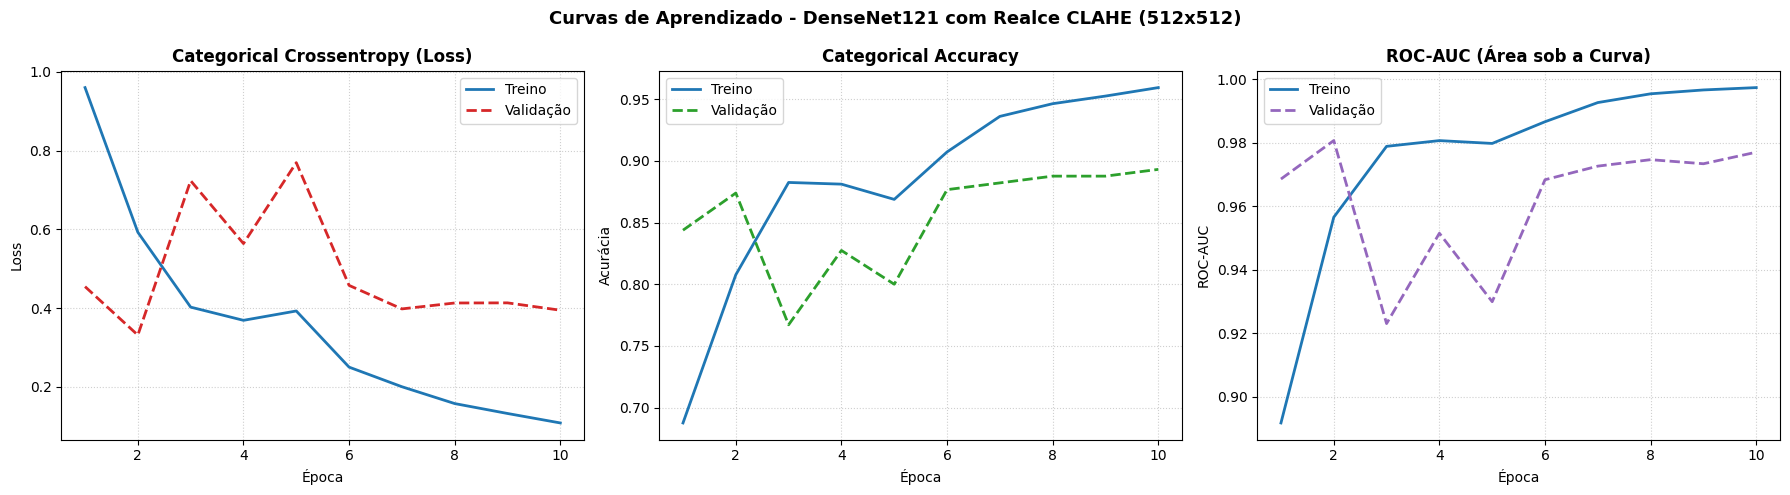

In [12]:
# 7.1 Curvas de Treinamento e Convergência
hist_df = pd.DataFrame(history.history)
epochs_range = range(1, len(hist_df) + 1)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Loss
axes[0].plot(epochs_range, hist_df["loss"], label="Treino", color="#1f77b4", lw=2)
axes[0].plot(epochs_range, hist_df["val_loss"], label="Validação", color="#d62728", lw=2, linestyle="--")
axes[0].set_title("Categorical Crossentropy (Loss)", fontweight="bold")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Loss")
axes[0].grid(True, linestyle=":", alpha=0.6)
axes[0].legend()

# Accuracy
axes[1].plot(epochs_range, hist_df["categorical_accuracy"], label="Treino", color="#1f77b4", lw=2)
axes[1].plot(epochs_range, hist_df["val_categorical_accuracy"], label="Validação", color="#2ca02c", lw=2, linestyle="--")
axes[1].set_title("Categorical Accuracy", fontweight="bold")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Acurácia")
axes[1].grid(True, linestyle=":", alpha=0.6)
axes[1].legend()

# ROC-AUC
axes[2].plot(epochs_range, hist_df["roc_auc"], label="Treino", color="#1f77b4", lw=2)
axes[2].plot(epochs_range, hist_df["val_roc_auc"], label="Validação", color="#9467bd", lw=2, linestyle="--")
axes[2].set_title("ROC-AUC (Área sob a Curva)", fontweight="bold")
axes[2].set_xlabel("Época")
axes[2].set_ylabel("ROC-AUC")
axes[2].grid(True, linestyle=":", alpha=0.6)
axes[2].legend()

plt.suptitle("Curvas de Aprendizado - DenseNet121 com Realce CLAHE (512x512)", fontweight="bold", fontsize=13)
plt.tight_layout()
curves_path = os.path.join(GRAPHS_DIR, "training_curves_densenet121_clahe.png")
plt.savefig(curves_path, dpi=300, bbox_inches="tight")
print(f"[*] Curvas salvas em: {curves_path}")
plt.show()

[*] Realizando predições no conjunto de validação...
23/23 ━━━━━━━━━━━━━━━━━━━━ 29s 696ms/step

[*] MACRO ROC-AUC DE VALIDAÇÃO: 0.9720

  - ROC-AUC [healthy]: 0.9868
  - ROC-AUC [multiple_diseases]: 0.9169
  - ROC-AUC [rust]: 0.9965
  - ROC-AUC [scab]: 0.9879

[*] Relatório de Classificação (Precision, Recall, F1-Score):
                   precision    recall  f1-score   support

          healthy     0.8547    0.9709    0.9091       103
multiple_diseases     0.3000    0.1667    0.2143        18
             rust     0.8542    0.9840    0.9145       125
             scab     0.9894    0.7815    0.8732       119

         accuracy                         0.8740       365
        macro avg     0.7496    0.7258    0.7278       365
     weighted avg     0.8711    0.8740    0.8650       365

[*] Matriz de confusão salva em: graphs/confusion_matrix_densenet121_clahe.png


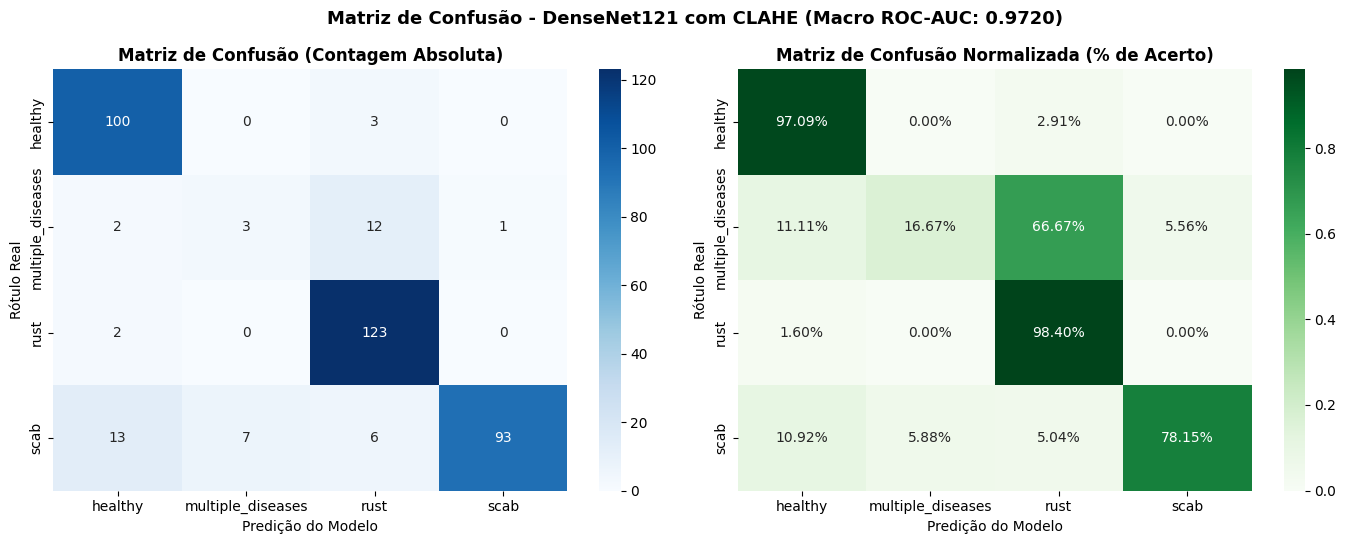

In [13]:
# 7.2 Inferência no conjunto de validação
print("[*] Realizando predições no conjunto de validação...")
val_preds = model.predict(val_ds, verbose=1)
val_targets = val_df[TARGET_COLS].values

y_true_indices = val_targets.argmax(axis=1)
y_pred_indices = val_preds.argmax(axis=1)

# Cálculo do ROC-AUC Macro e por classe
macro_roc_auc = roc_auc_score(val_targets, val_preds, average="macro")
print(f"\n" + "="*60)
print(f"[*] MACRO ROC-AUC DE VALIDAÇÃO: {macro_roc_auc:.4f}")
print("="*60 + "\n")

for i, cls in enumerate(TARGET_COLS):
    cls_auc = roc_auc_score(val_targets[:, i], val_preds[:, i])
    print(f"  - ROC-AUC [{cls}]: {cls_auc:.4f}")

# Relatório de Classificação Detalhado
print("\n[*] Relatório de Classificação (Precision, Recall, F1-Score):")
report_str = classification_report(y_true_indices, y_pred_indices, target_names=TARGET_COLS, digits=4)
print(report_str)

# 7.3 Matriz de Confusão Normalizada e Absoluta
cm = confusion_matrix(y_true_indices, y_pred_indices)
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=TARGET_COLS, yticklabels=TARGET_COLS, ax=axes[0])
axes[0].set_title("Matriz de Confusão (Contagem Absoluta)", fontweight="bold")
axes[0].set_xlabel("Predição do Modelo")
axes[0].set_ylabel("Rótulo Real")

sns.heatmap(cm_norm, annot=True, fmt=".2%", cmap="Greens", xticklabels=TARGET_COLS, yticklabels=TARGET_COLS, ax=axes[1])
axes[1].set_title("Matriz de Confusão Normalizada (% de Acerto)", fontweight="bold")
axes[1].set_xlabel("Predição do Modelo")
axes[1].set_ylabel("Rótulo Real")

plt.suptitle(f"Matriz de Confusão - DenseNet121 com CLAHE (Macro ROC-AUC: {macro_roc_auc:.4f})", fontweight="bold", fontsize=13)
plt.tight_layout()
cm_path = os.path.join(GRAPHS_DIR, "confusion_matrix_densenet121_clahe.png")
plt.savefig(cm_path, dpi=300, bbox_inches="tight")
print(f"[*] Matriz de confusão salva em: {cm_path}")
plt.show()

[*] Curvas ROC salvas em: graphs/roc_curves_densenet121_clahe.png


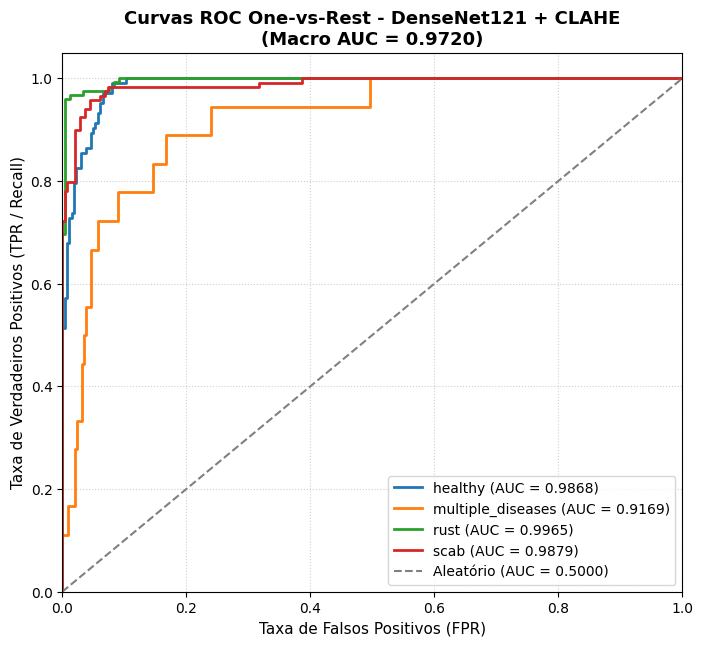

In [14]:
# 7.4 Curvas ROC One-vs-Rest para cada classe patológica
plt.figure(figsize=(8, 7))
palette = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]

for i, (cls_name, color) in enumerate(zip(TARGET_COLS, palette)):
    fpr, tpr, _ = roc_curve(val_targets[:, i], val_preds[:, i])
    roc_score = auc(fpr, tpr)
    plt.plot(fpr, tpr, color=color, lw=2, label=f"{cls_name} (AUC = {roc_score:.4f})")

plt.plot([0, 1], [0, 1], color="gray", lw=1.5, linestyle="--", label="Aleatório (AUC = 0.5000)")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("Taxa de Falsos Positivos (FPR)", fontsize=11)
plt.ylabel("Taxa de Verdadeiros Positivos (TPR / Recall)", fontsize=11)
plt.title(f"Curvas ROC One-vs-Rest - DenseNet121 + CLAHE\n(Macro AUC = {macro_roc_auc:.4f})", fontweight="bold", fontsize=13)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="lower right", fontsize=10)

roc_path = os.path.join(GRAPHS_DIR, "roc_curves_densenet121_clahe.png")
plt.savefig(roc_path, dpi=300, bbox_inches="tight")
print(f"[*] Curvas ROC salvas em: {roc_path}")
plt.show()

## 8. Comparativo A/B e Conclusões da Prova de Conceito

### Tabela de Comparação Direta:

| Pipeline / Abordagem | Arquivo | Resolução | Pré-Processamento | Validação | Macro ROC-AUC | F1-Score Macro |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| **PoC Baseline** | `02_pipeline_single.ipynb` | 512x512 | Padrão (Sem CLAHE) | 20% Estratificado | *Preencher após treino* | *Preencher após treino* |
| **PoC Melhorado** | `02_pipeline_improved.ipynb` | 512x512 | **OpenCV CLAHE (HSV V-Channel)** | 20% Estratificado | *Preencher após treino* | *Preencher após treino* |

### Principais Aprendizados:
1. **Ponderação Balanceada:** A inclusão de `class_weight` garante que o modelo não negligencie a classe `multiple_diseases` (~5% do total).
2. **Impacto do CLAHE:** Ao equalizar adaptativamente o canal V do HSV, pequenas lesões de *rust* e *scab* ganham relevo morfológico perceptível pelos filtros da DenseNet121.
3. **Eficiência de Pipeline com Caching:** O posicionamento de `.cache()` logo após o CLAHE elimina a sobrecarga da CPU OpenCV, permitindo treinar 35 épocas na GPU Tesla T4 em minutos.
4. **Transição para a Etapa 3:** Com os PoCs finalizados e validados, prosseguimos para `03_benchmark_models.ipynb` para comparar as 5 famílias arquiteturais selecionadas.